# Correlação dos genes com a idade

Procura, entre todos os genes dos conjuntos, os que têm maior correlação com a idade e verifica a relação deles com o melhor modelo da parte 2 de `model.ipynb`: a regressão logística única, com os grupos de idade e peso 3 nas amostras erradas. O modelo não é treinado de novo: ele é carregado do arquivo que `model.ipynb` salva.

Análises:

1. Correlação de Spearman entre a expressão de cada gene e o grupo de idade, no treino, e os `TOP_GENES` genes com maior correlação.
2. Correlação desses genes com a idade dentro de cada região.
3. Correlação entre esses genes.
4. Os mesmos genes na validação: a correlação com a idade se repete em amostras que não foram usadas para escolher os genes?
5. Peso desses genes no melhor modelo: eles têm coeficientes maiores do que os outros genes?

Usa os conjuntos gerados por `data_preparation.ipynb`. As correlações do treino usam só as amostras originais, sem as cópias sintéticas do oversampling, para não contar a mesma amostra mais de uma vez.

In [1]:
# Settings shared by the whole notebook
class Config:
    MAX_RAM_GB = 12
    SIGNIFICANCE_LEVEL = 0.05
    TOP_GENES = 30
    AGE_GROUPS = {
        "20-49": ["20-29", "30-39", "40-49"],
        "50-59": ["50-59"],
        "60-79": ["60-69", "70-79"],
    }

In [2]:
# Memory limit, imports and project paths
import resource

max_bytes = Config.MAX_RAM_GB * 1024**3
resource.setrlimit(resource.RLIMIT_AS, (max_bytes, max_bytes))

import sys
sys.path.append("..")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import mannwhitneyu, t
from sklearn.metrics import accuracy_score, f1_score

from src.config import BEST_MODEL_FILE, BrainRegions, L1_REGULATORS
from src.data.loader import load_splits

## Dados

Os genes dos conjuntos estão identificados pelo código Ensembl. O nome de cada gene vem da coluna `Description` de um dos arquivos `.gct`.

In [3]:
# Load the splits, recode the age ranges into age groups and map Ensembl IDs to gene symbols
GROUP_LABELS = {code: group for code, group in enumerate(Config.AGE_GROUPS, start=1)}
AGE_TO_GROUP = {age: code for code, ages in enumerate(Config.AGE_GROUPS.values(), start=1) for age in ages}

splits = load_splits()
X_train, _, info_train = splits["train"]
X_val, _, info_val = splits["val"]
y_train = info_train["AGE"].map(AGE_TO_GROUP).astype(int)
y_val = info_val["AGE"].map(AGE_TO_GROUP).astype(int)

symbols = pd.read_csv(next(iter(BrainRegions)).file, sep="\t", skiprows=2, usecols=["Name", "Description"])
symbols = symbols.set_index("Name")["Description"].reindex(X_train.columns)

original = (info_train["origem"] == "Original").to_numpy()
X_original, y_original, info_original = X_train[original], y_train[original], info_train[original]
print(f"Genes: {X_train.shape[1]} | amostras originais do treino: {len(X_original)} | amostras da validação: {len(X_val)}")

Genes: 17500 | amostras originais do treino: 1577 | amostras da validação: 658


## 1. Genes com maior correlação com a idade

Correlação de Spearman (ordinal, não exige distribuição normal) entre a expressão de cada gene e o grupo de idade, nas amostras originais do treino. A correlação de Spearman é a correlação de Pearson calculada sobre os postos (ranks) dos valores, e é feita para todos os genes de uma vez. O p-value usa a mesma aproximação da distribuição t do `scipy.stats.spearmanr` e é corrigido por Bonferroni, porque são testados todos os genes ao mesmo tempo.

In [4]:
# Spearman correlation of every gene with a target, computed for all genes at once
def spearman_all_genes(X, target):
    rho = X.rank().corrwith(pd.Series(target, index=X.index).rank())
    n = len(X)
    t_stat = rho * np.sqrt((n - 2) / (1 - rho.clip(-0.999999, 0.999999) ** 2))
    p_value = 2 * t.sf(np.abs(t_stat), df=n - 2)
    result = pd.DataFrame({"Gene": symbols[rho.index].values, "rho": rho.values, "p": p_value}, index=rho.index)
    result["p corrigido (Bonferroni)"] = (result["p"] * len(result)).clip(upper=1)
    result["Significativo"] = result["p corrigido (Bonferroni)"] < Config.SIGNIFICANCE_LEVEL
    result["Regulador de L1"] = result["Gene"].isin(L1_REGULATORS)
    return result.sort_values("rho", key=np.abs, ascending=False)


age_correlation = spearman_all_genes(X_original, y_original)
top_ids = age_correlation.index[:Config.TOP_GENES]

print(f"Genes com correlação significativa com a idade: {age_correlation['Significativo'].sum()} de {len(age_correlation)}")
print(f"Correlação positiva (aumentam com a idade): {(age_correlation['Significativo'] & (age_correlation['rho'] > 0)).sum()}")
print(f"Correlação negativa (diminuem com a idade): {(age_correlation['Significativo'] & (age_correlation['rho'] < 0)).sum()}")
age_correlation.head(Config.TOP_GENES).round(4)

Genes com correlação significativa com a idade: 2312 de 17500
Correlação positiva (aumentam com a idade): 230
Correlação negativa (diminuem com a idade): 2082


,Gene,rho,p,p corrigido (Bonferroni),Significativo,Regulador de L1
Name,,,,,,
ENSG00000124762.15,CDKN1A,0.2451,0.0,0.0,True,False
ENSG00000155659.15,VSIG4,0.2380,0.0,0.0,True,False
ENSG00000074211.14,PPP2R2C,-0.2252,0.0,0.0,True,False
ENSG00000176273.15,SLC35G1,-0.2228,0.0,0.0,True,False
ENSG00000110077.16,MS4A6A,0.2207,0.0,0.0,True,False
ENSG00000012223.13,LTF,0.2198,0.0,0.0,True,False
ENSG00000114999.8,TTL,-0.2164,0.0,0.0,True,False
ENSG00000132470.14,ITGB4,0.2131,0.0,0.0,True,False
ENSG00000130513.7,GDF15,0.2123,0.0,0.0,True,False


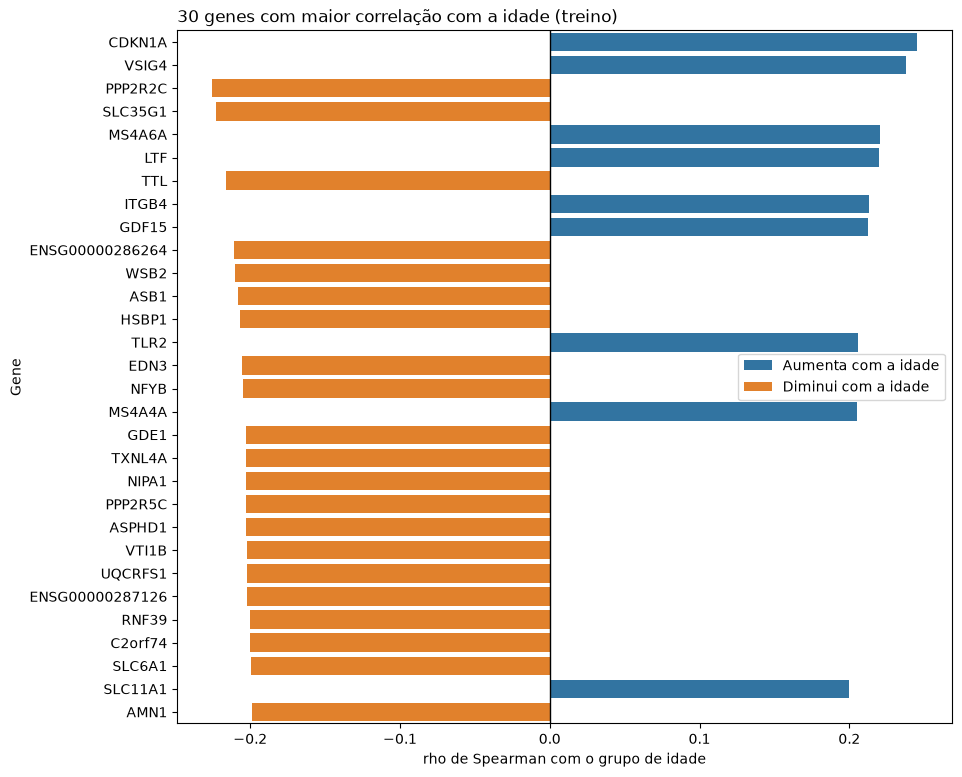

In [5]:
# Bar plot of the genes with the strongest correlation with the age group
top = age_correlation.head(Config.TOP_GENES)
plt.figure(figsize=(10, 9))
sns.barplot(x=top["rho"], y=top["Gene"], hue=np.where(top["rho"] > 0, "Aumenta com a idade", "Diminui com a idade"),
            hue_order=["Aumenta com a idade", "Diminui com a idade"], dodge=False)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("rho de Spearman com o grupo de idade")
plt.ylabel("Gene")
plt.title(f"{Config.TOP_GENES} genes com maior correlação com a idade (treino)", loc="left")
plt.legend(title="")
plt.show()

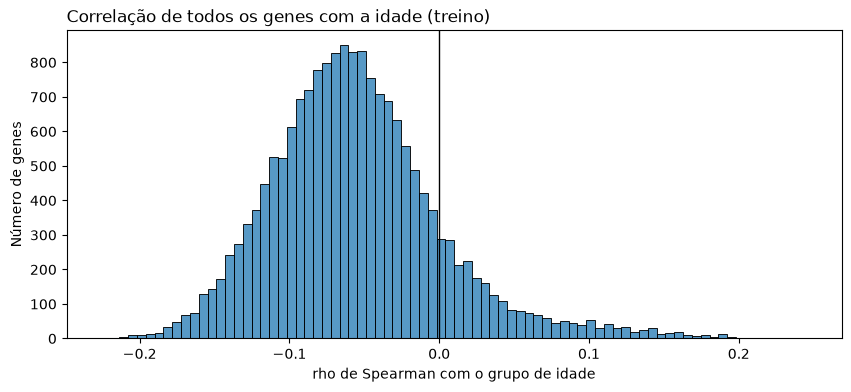

In [6]:
# Distribution of the correlation of all genes with the age group
plt.figure(figsize=(10, 4))
sns.histplot(age_correlation["rho"], bins=80)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("rho de Spearman com o grupo de idade")
plt.ylabel("Número de genes")
plt.title("Correlação de todos os genes com a idade (treino)", loc="left")
plt.show()

## 2. Correlação com a idade dentro de cada região

A expressão muda muito de uma região para outra, então a correlação dos genes com maior correlação geral também é calculada separadamente em cada região. Um gene cuja correlação aparece em várias regiões é um resultado mais confiável do que um gene que só aparece no total.

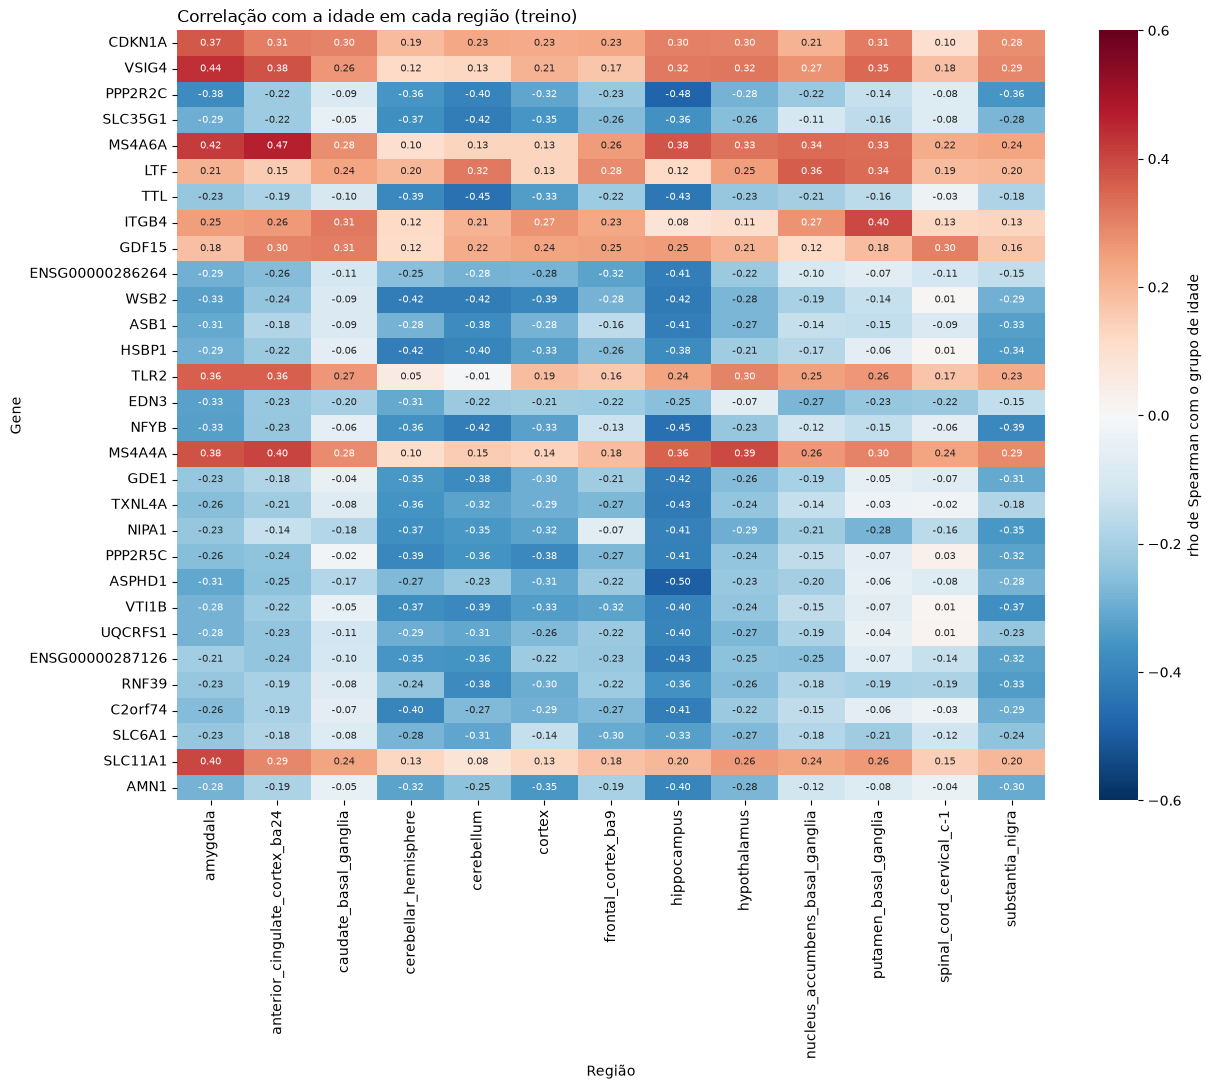

Name,CDKN1A,VSIG4,PPP2R2C,SLC35G1,MS4A6A,LTF,TTL,ITGB4,GDF15,ENSG00000286264,...,ASPHD1,RNF39,AMN1,C2orf74,WSB2,HSBP1,TLR2,PPP2R5C,VTI1B,UQCRFS1
Regiões com o mesmo sinal da correlação geral,13,13,13,13,13,13,13,13,13,13,...,13,13,13,13,12,12,12,12,12,12


In [7]:
# Spearman correlation with the age group inside each region, for the top genes
region_rho = pd.DataFrame({
    region: X_original.loc[(info_original["region"] == region).to_numpy(), top_ids].rank().corrwith(
        y_original[(info_original["region"] == region).to_numpy()].rank()
    )
    for region in sorted(info_original["region"].unique())
}).rename(index=symbols)

plt.figure(figsize=(14, 10))
sns.heatmap(region_rho, cmap="RdBu_r", center=0, vmin=-0.6, vmax=0.6, annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"label": "rho de Spearman com o grupo de idade"})
plt.xlabel("Região")
plt.ylabel("Gene")
plt.title("Correlação com a idade em cada região (treino)", loc="left")
plt.show()

same_sign = (np.sign(region_rho).eq(np.sign(age_correlation.loc[top_ids, "rho"].values), axis=0)).sum(axis=1)
same_sign.rename("Regiões com o mesmo sinal da correlação geral").sort_values(ascending=False).to_frame().T

## 3. Correlação entre os genes com maior correlação com a idade

Matriz de correlação de Spearman entre esses genes, nas amostras originais do treino. O `clustermap` agrupa os genes que variam juntos.

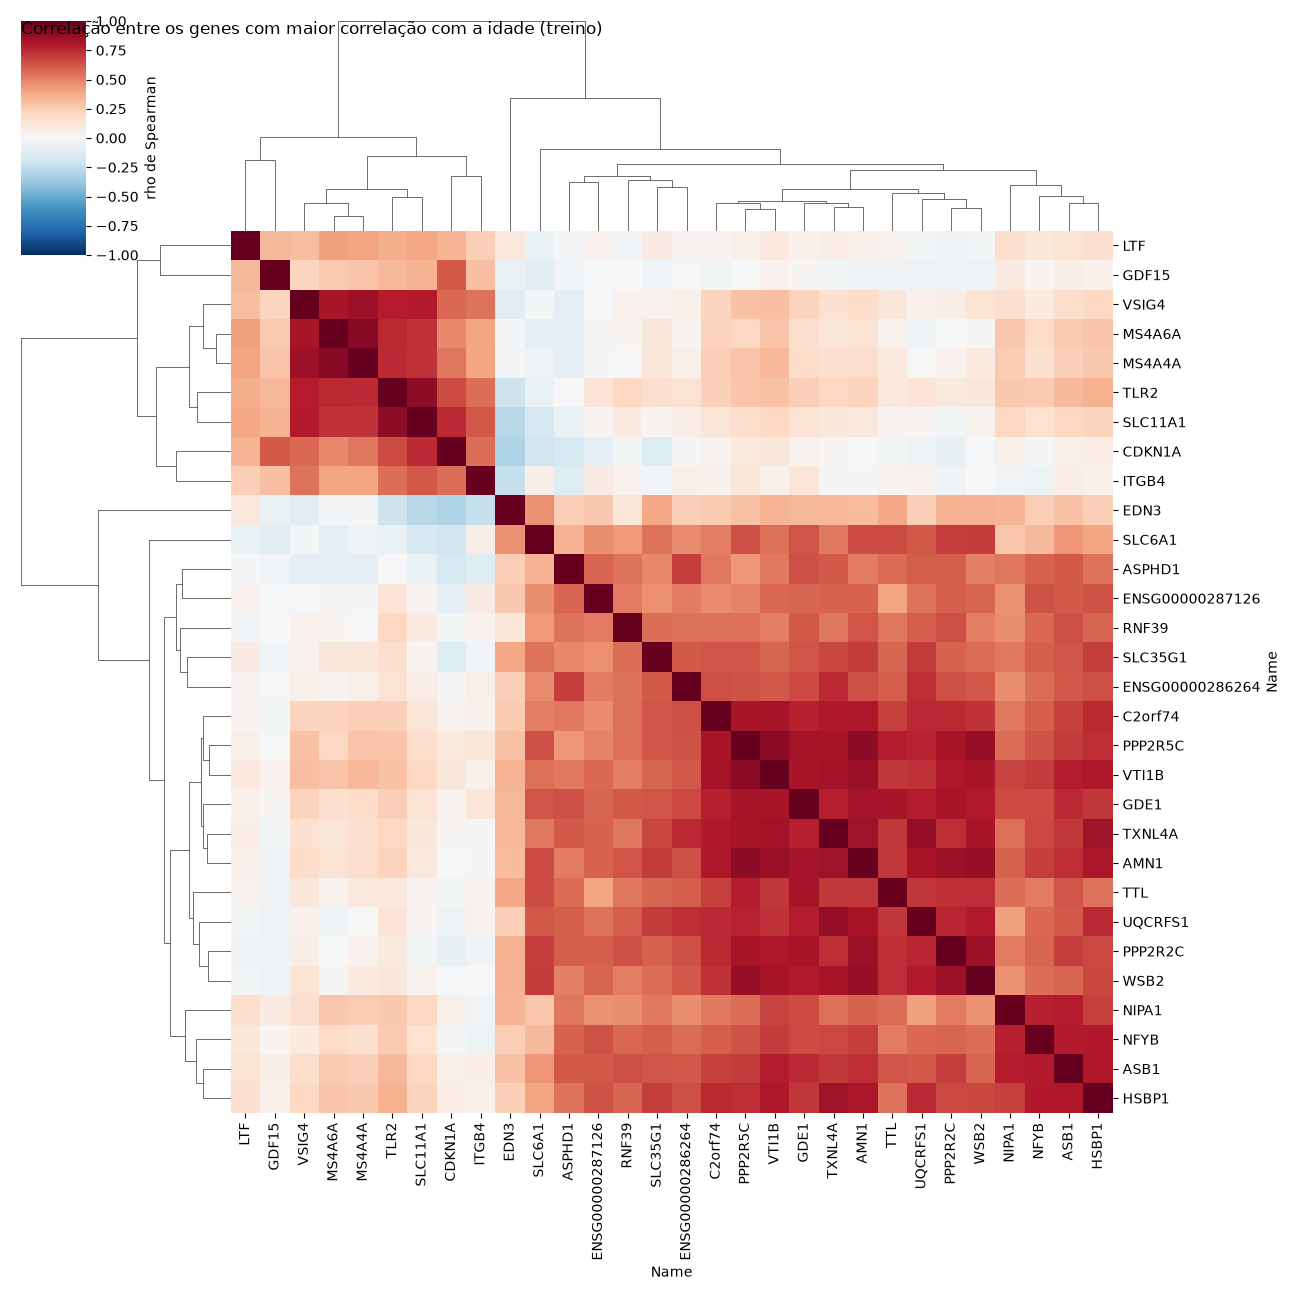

rho
Name    Name          
MS4A6A  MS4A4A   0.914
PPP2R5C VTI1B    0.894
        AMN1     0.891
TLR2    SLC11A1  0.886
TXNL4A  UQCRFS1  0.880
WSB2    PPP2R5C  0.871
        AMN1     0.868
VTI1B   AMN1     0.866
PPP2R2C AMN1     0.856
        WSB2     0.855
VSIG4   MS4A4A   0.852
HSBP1   TXNL4A   0.851
TXNL4A  AMN1     0.849
        VTI1B    0.842
GDE1    AMN1     0.834
        PPP2R5C  0.834
TTL     GDE1     0.833
VTI1B   C2orf74  0.829
VSIG4   MS4A6A   0.826
PPP2R2C GDE1     0.825
WSB2    TXNL4A   0.825
UQCRFS1 AMN1     0.824
WSB2    VTI1B    0.823
GDE1    VTI1B    0.822
PPP2R2C PPP2R5C  0.821
PPP2R5C C2orf74  0.821
TXNL4A  PPP2R5C  0.820
HSBP1   AMN1     0.814
        VTI1B    0.811
C2orf74 AMN1     0.810

In [8]:
# Spearman correlation matrix between the top genes, clustered
top_corr = X_original[top_ids].rename(columns=symbols).corr(method="spearman")

grid = sns.clustermap(top_corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, figsize=(13, 13),
                      xticklabels=True, yticklabels=True, cbar_kws={"label": "rho de Spearman"})
grid.fig.suptitle("Correlação entre os genes com maior correlação com a idade (treino)", x=0.02, ha="left")
plt.show()

pairs = top_corr.where(np.triu(np.ones(top_corr.shape, dtype=bool), k=1)).stack()
pairs.sort_values(key=np.abs, ascending=False).head(Config.TOP_GENES).rename("rho").to_frame().round(3)

## 4. Os mesmos genes na validação

Os 30 genes foram escolhidos no treino, entre 17500 genes. Ao escolher os maiores valores entre tantos, alguns genes entram na lista por acaso. Para verificar, calculamos a correlação de Spearman dos mesmos 30 genes com o grupo de idade nas amostras da validação, que não foram usadas para escolhê-los. A correção de Bonferroni aqui considera só os 30 genes testados.

In [9]:
# Spearman correlation of the same top genes with the age group in the validation set
val_correlation = X_val[top_ids].rank().corrwith(y_val.rank())
n_val = len(X_val)
t_val = val_correlation * np.sqrt((n_val - 2) / (1 - val_correlation.clip(-0.999999, 0.999999) ** 2))
p_val = pd.Series(2 * t.sf(np.abs(t_val), df=n_val - 2), index=top_ids)

top_validation = pd.DataFrame({
    "Gene": symbols[top_ids].values,
    "rho no treino": age_correlation.loc[top_ids, "rho"].values,
    "rho na validação": val_correlation.values,
    "p corrigido na validação (Bonferroni)": (p_val * len(top_ids)).clip(upper=1).values,
}, index=top_ids)
top_validation["Mesmo sinal"] = np.sign(top_validation["rho no treino"]) == np.sign(top_validation["rho na validação"])
top_validation["Significativo na validação"] = top_validation["p corrigido na validação (Bonferroni)"] < Config.SIGNIFICANCE_LEVEL

print(f"Genes com o mesmo sinal no treino e na validação: {top_validation['Mesmo sinal'].sum()} de {len(top_validation)}")
print(f"Genes significativos na validação: {top_validation['Significativo na validação'].sum()} de {len(top_validation)}")
print(f"Média de |rho|: treino = {top_validation['rho no treino'].abs().mean():.3f}, validação = {top_validation['rho na validação'].abs().mean():.3f}")
top_validation.round(4)

Genes com o mesmo sinal no treino e na validação: 26 de 30
Genes significativos na validação: 4 de 30
Média de |rho|: treino = 0.210, validação = 0.066


,Gene,rho no treino,rho na validação,p corrigido na validação (Bonferroni),Mesmo sinal,Significativo na validação
Name,,,,,,
ENSG00000124762.15,CDKN1A,0.2451,0.0454,1.0000,True,False
ENSG00000155659.15,VSIG4,0.2380,0.1257,0.0370,True,True
ENSG00000074211.14,PPP2R2C,-0.2252,-0.0994,0.3214,True,False
ENSG00000176273.15,SLC35G1,-0.2228,-0.0573,1.0000,True,False
ENSG00000110077.16,MS4A6A,0.2207,0.1716,0.0003,True,True
ENSG00000012223.13,LTF,0.2198,-0.0478,1.0000,False,False
ENSG00000114999.8,TTL,-0.2164,0.0074,1.0000,False,False
ENSG00000132470.14,ITGB4,0.2131,0.1123,0.1179,True,False
ENSG00000130513.7,GDF15,0.2123,0.0604,1.0000,True,False


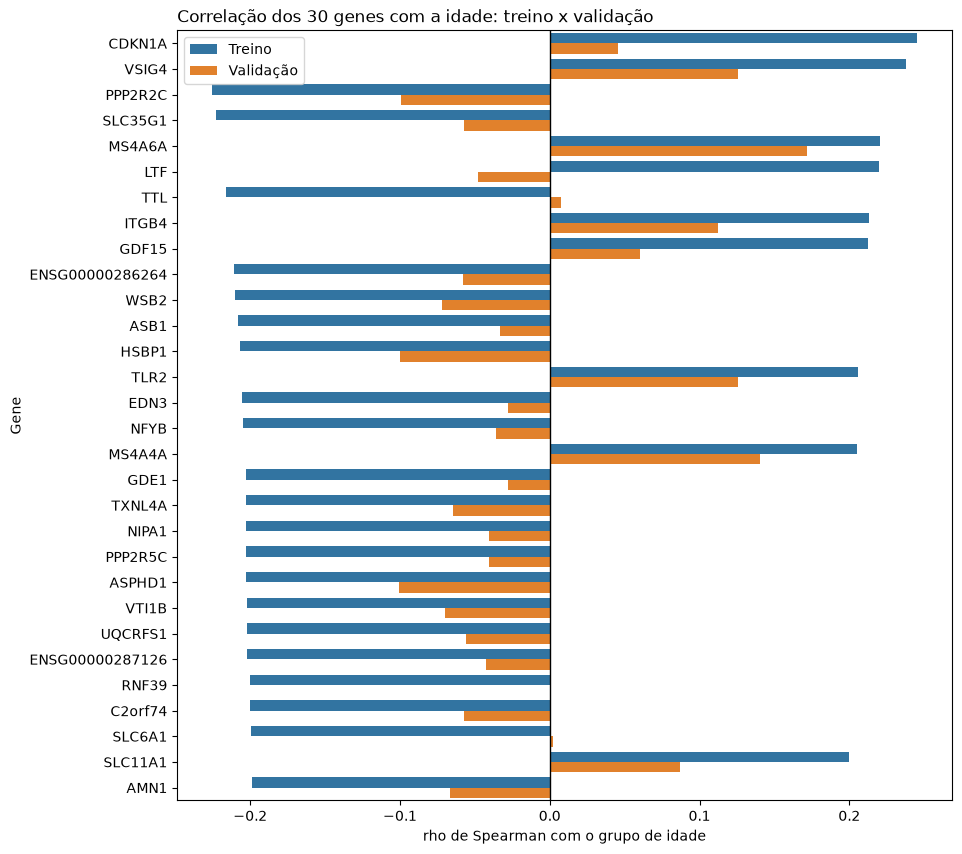

In [10]:
# rho of each top gene in the training set and in the validation set
plot_data = top_validation.melt(id_vars="Gene", value_vars=["rho no treino", "rho na validação"],
                                var_name="Conjunto", value_name="rho")
plot_data["Conjunto"] = plot_data["Conjunto"].map({"rho no treino": "Treino", "rho na validação": "Validação"})

plt.figure(figsize=(10, 10))
sns.barplot(data=plot_data, x="rho", y="Gene", hue="Conjunto", order=top_validation["Gene"])
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("rho de Spearman com o grupo de idade")
plt.ylabel("Gene")
plt.title(f"Correlação dos {Config.TOP_GENES} genes com a idade: treino x validação", loc="left")
plt.legend(title="")
plt.show()

## 5. Peso desses genes no melhor modelo

O melhor modelo é carregado do arquivo salvo pela parte 2 de `model.ipynb`. Por isso, rode antes a célula que salva o modelo em `model.ipynb`.

Como os genes estão padronizados, o tamanho do coeficiente indica o quanto cada gene pesa na decisão do modelo. A importância de um gene é o maior valor absoluto dos seus coeficientes entre os 3 grupos de idade. O teste de Mann-Whitney (aula da semana 13) verifica se os genes com maior correlação com a idade têm importância maior do que os outros genes.

In [11]:
# Load the best model saved by model.ipynb (no retraining) and check it on the validation set
saved = joblib.load(BEST_MODEL_FILE)
assert saved["age_groups"] == Config.AGE_GROUPS, "The saved model uses different age groups than Config.AGE_GROUPS"
best_model = saved["model"]
print(f"Modelo carregado: peso {saved['misclassified_weight']} nas amostras erradas")

val_pred = best_model.predict(X_val)
print(f"F1 macro na validação: {f1_score(y_val, val_pred, average='macro') * 100:.2f}%")
print(f"Acurácia na validação: {accuracy_score(y_val, val_pred) * 100:.2f}%")

Modelo carregado: peso 3 nas amostras erradas
F1 macro na validação: 59.09%
Acurácia na validação: 62.01%


In [12]:
# Gene importance (largest absolute coefficient) and Mann-Whitney test: top correlated genes vs other genes
coefficients = pd.DataFrame(best_model.named_steps["clf"].coef_.T, index=X_train.columns,
                            columns=[GROUP_LABELS[code] for code in best_model.named_steps["clf"].classes_])
importance = coefficients.abs().max(axis=1)
rank = importance.rank(ascending=False).astype(int)
is_top = importance.index.isin(top_ids)

top_importance = pd.DataFrame({
    "Gene": symbols[top_ids].values,
    "rho com a idade": age_correlation.loc[top_ids, "rho"].values,
    "Importância": importance[top_ids].values,
    "Posição entre todos os genes": rank[top_ids].values,
    **{f"Coeficiente {group}": coefficients.loc[top_ids, group].values for group in coefficients.columns},
}).sort_values("Importância", ascending=False)

stat, p_value = mannwhitneyu(importance[is_top], importance[~is_top], alternative="greater")
print(f"Mediana da importância: genes com maior correlação = {importance[is_top].median():.5f}, outros genes = {importance[~is_top].median():.5f}")
print(f"Mann-Whitney (genes com maior correlação > outros genes): p = {p_value:.4f}")
if p_value < Config.SIGNIFICANCE_LEVEL:
    print(f"Os genes com maior correlação com a idade têm importância significativamente maior no modelo (p < {Config.SIGNIFICANCE_LEVEL}).")
else:
    print(f"Não há evidência de que esses genes pesem mais no modelo do que os outros (p >= {Config.SIGNIFICANCE_LEVEL}).")

most_important = importance.sort_values(ascending=False).index[:Config.TOP_GENES]
print(f"Genes em comum entre os {Config.TOP_GENES} mais correlacionados e os {Config.TOP_GENES} mais importantes no modelo: "
      f"{sorted(symbols[top_ids.intersection(most_important)])}")
top_importance.round(4)

Mediana da importância: genes com maior correlação = 0.02619, outros genes = 0.01558
Mann-Whitney (genes com maior correlação > outros genes): p = 0.0006
Os genes com maior correlação com a idade têm importância significativamente maior no modelo (p < 0.05).
Genes em comum entre os 30 mais correlacionados e os 30 mais importantes no modelo: ['GDF15']


,Gene,rho com a idade,Importância,Posição entre todos os genes,Coeficiente 20-49,Coeficiente 50-59,Coeficiente 60-79
8,GDF15,0.2123,0.1471,8,-0.1187,-0.0284,0.1471
25,RNF39,-0.2003,0.1154,38,0.0909,0.0245,-0.1154
5,LTF,0.2198,0.0909,105,-0.0648,-0.0260,0.0909
0,CDKN1A,0.2451,0.0797,194,-0.0461,-0.0336,0.0797
26,C2orf74,-0.2002,0.0656,375,0.0140,0.0516,-0.0656
1,VSIG4,0.2380,0.0653,378,-0.0500,-0.0153,0.0653
4,MS4A6A,0.2207,0.0592,517,-0.0558,-0.0035,0.0592
7,ITGB4,0.2131,0.0581,560,-0.0534,-0.0047,0.0581
16,MS4A4A,0.2048,0.0552,677,-0.0552,0.0014,0.0539
24,ENSG00000287126,-0.2018,0.0368,2092,0.0337,0.0032,-0.0368


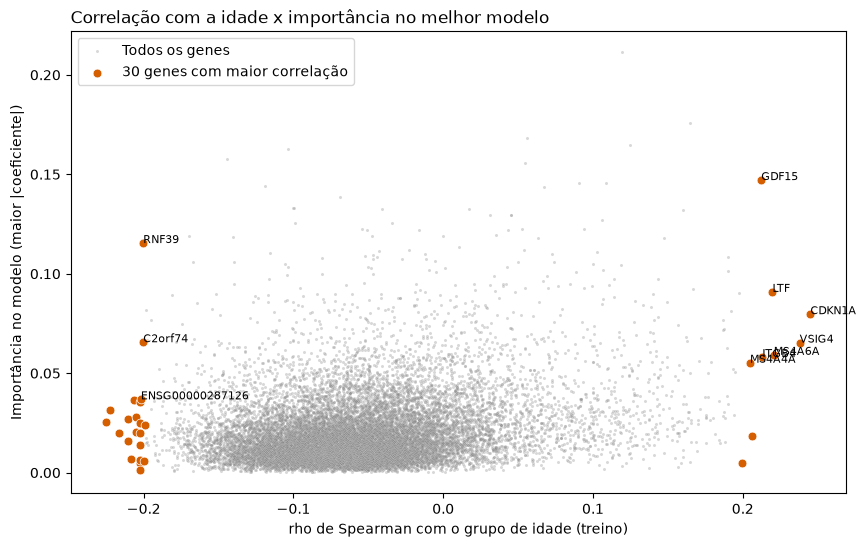

In [13]:
# Correlation with the age vs importance in the model, one point per gene
plt.figure(figsize=(10, 6))
sns.scatterplot(x=age_correlation["rho"], y=importance[age_correlation.index], color="gray", s=5, alpha=0.3, label="Todos os genes")
sns.scatterplot(x=age_correlation.loc[top_ids, "rho"], y=importance[top_ids], color="#d55e00", s=40,
                label=f"{Config.TOP_GENES} genes com maior correlação")
for _, row in top_importance.head(10).iterrows():
    plt.annotate(row["Gene"], (row["rho com a idade"], row["Importância"]), fontsize=8)
plt.xlabel("rho de Spearman com o grupo de idade (treino)")
plt.ylabel("Importância no modelo (maior |coeficiente|)")
plt.title("Correlação com a idade x importância no melhor modelo", loc="left")
plt.legend()
plt.show()

## 6. Função dos genes com correlação significativa na validação

Dos 30 genes escolhidos no treino, só 4 mantêm correlação significativa com o grupo de idade na validação (correção de Bonferroni para os 30 testes). Os 4 aumentam com a idade, no treino e na validação. As descrições resumem o texto do NCBI Gene (RefSeq), que é o mesmo exibido pelo GeneCards na seção "Entrez Gene Summary". Os valores são os desta execução do notebook.

| Gene | rho no treino | rho na validação | p corrigido na validação |
|---|---|---|---|
| MS4A6A | +0,221 | +0,172 | 0,0003 |
| MS4A4A | +0,205 | +0,141 | 0,0089 |
| TLR2 | +0,206 | +0,126 | 0,0366 |
| VSIG4 | +0,238 | +0,126 | 0,0370 |

### MS4A6A (membrane spanning 4-domains A6A), cromossomo 11

- **Função:** membro da família de genes MS4A (membrane-spanning 4A). As proteínas dessa família têm estrutura em comum e padrões de expressão próprios em células hematopoéticas (do sangue e do sistema imune) e em tecidos não linfoides. O gene fica na região 11q12.1, junto de outros membros da família.
- **Fonte:** [GeneCards: MS4A6A](https://www.genecards.org/cgi-bin/carddisp.pl?gene=MS4A6A) (resumo Entrez/RefSeq; [NCBI Gene 64231](https://www.ncbi.nlm.nih.gov/gene/64231))

### MS4A4A (membrane spanning 4-domains A4A), cromossomo 11

- **Função:** também membro da família MS4A, com as mesmas características estruturais e expressão em células hematopoéticas e em tecidos não linfoides.
- **Fonte:** [GeneCards: MS4A4A](https://www.genecards.org/cgi-bin/carddisp.pl?gene=MS4A4A) (resumo Entrez/RefSeq; [NCBI Gene 51338](https://www.ncbi.nlm.nih.gov/gene/51338))

### TLR2 (toll like receptor 2), cromossomo 4

- **Função:** membro da família dos receptores Toll-like (TLR), que têm papel fundamental no reconhecimento de patógenos e na ativação da imunidade inata. É uma proteína da superfície da célula que se combina com outros TLRs para reconhecer moléculas conservadas de microrganismos (PAMPs). Essa ativação aumenta a sinalização que modula a resposta inflamatória. Também parece promover apoptose em resposta a lipoproteínas bacterianas e já foi associado a várias doenças autoimunes.
- **Fonte:** [GeneCards: TLR2](https://www.genecards.org/cgi-bin/carddisp.pl?gene=TLR2) (resumo Entrez/RefSeq; [NCBI Gene 7097](https://www.ncbi.nlm.nih.gov/gene/7097))

### VSIG4 (V-set and immunoglobulin domain containing 4), cromossomo X

- **Função:** proteína com domínios V-set e de imunoglobulina, estruturalmente relacionada à família B7 de proteínas reguladoras do sistema imune. Pode atuar como regulador negativo das respostas de células T e é receptor dos fragmentos C3b e iC3b do componente 3 do sistema complemento.
- **Fonte:** [GeneCards: VSIG4](https://www.genecards.org/cgi-bin/carddisp.pl?gene=VSIG4) (resumo Entrez/RefSeq; [NCBI Gene 11326](https://www.ncbi.nlm.nih.gov/gene/11326))